In [2]:
# =========================================================
# ROLL NO: 24BAD077
# NAME: Navithanjali M S
# PART A: DATASET PREPARATION (FIXED FOR HF DEPRECATION)
# ROLL NO: 24BAD077
# =========================================================
import urllib.request
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences
from sklearn.model_selection import train_test_split
print("--- PART A START ---")
# 1. Direct raw download of Tiny Shakespeare dataset
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
with urllib.request.urlopen(url) as response:
    raw_text = response.read().decode('utf-8')
# 2. Explore the dataset and examine text samples
print(f"Total dataset length (characters): {len(raw_text)}")
print("Sample text snippet:\n", raw_text[:250])
# 3. Convert text to lowercase and take a subset for efficient execution
text_sample = raw_text[:50000].lower()
# 4. Tokenize the text into individual words
tokenizer = Tokenizer(oov_token='<OOV>')
tokenizer.fit_on_texts([text_sample])
# 5. Build vocabulary and assign unique integer index to each word
word_index = tokenizer.word_index
total_words = len(word_index) + 1  # +1 for 0 padding index
print(f"Vocabulary Size: {total_words}")
# 6. Generate input sequences for next-word prediction
input_sequences = []
sentences = text_sample.split('\n')
for line in sentences:
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)
# 7. Apply sequence padding to obtain inputs of equal length
max_sequence_len = max([len(x) for x in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))
# Separate features (X) and labels (y)
X = input_sequences[:, :-1]
y = input_sequences[:, -1]
# 8. Split into training and validation datasets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Max Sequence Length: {max_sequence_len}")
print(f"Training Samples Shape: {X_train.shape}")
print(f"Validation Samples Shape: {X_val.shape}")
print("--- PART A COMPLETED ---")

--- PART A START ---
Total dataset length (characters): 1115394
Sample text snippet:
 First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

Vocabulary Size: 2082
Max Sequence Length: 12
Training Samples Shape: (5991, 11)
Validation Samples Shape: (1498, 11)
--- PART A COMPLETED ---


In [3]:
# =========================================================
# PART B: IMPLEMENTING THE RNN MODEL
# ROLL NO: [Insert Your Roll Number Here]
# =========================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

print("--- PART B START ---")

model = Sequential([
    # 1. Embedding layer to convert word indices to dense vectors
    Embedding(input_dim=total_words, output_dim=64, input_length=max_sequence_len - 1),

    # 2. Simple RNN layer to learn sequential dependencies
    SimpleRNN(128, return_sequences=False),

    # 3. Dense output layer with Softmax activation for next-word prediction
    Dense(total_words, activation='softmax')
])

# 4. Compile the model
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# 5. Display model summary
print("\n--- MODEL ARCHITECTURE SUMMARY ---")
model.summary()
print("--- PART B COMPLETED ---")

--- PART B START ---

--- MODEL ARCHITECTURE SUMMARY ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

--- PART B COMPLETED ---


--- PART C START ---
Epoch 1/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.0409 - loss: 6.8910 - val_accuracy: 0.0381 - val_loss: 6.6958
Epoch 2/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.0439 - loss: 6.3673 - val_accuracy: 0.0381 - val_loss: 6.7965
Epoch 3/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.0439 - loss: 6.3179 - val_accuracy: 0.0381 - val_loss: 6.8528
Epoch 4/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.0439 - loss: 6.2591 - val_accuracy: 0.0381 - val_loss: 6.7985
Epoch 5/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.0487 - loss: 6.1587 - val_accuracy: 0.0427 - val_loss: 6.7437
Epoch 6/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.0529 - loss: 6.0314 - val_accuracy: 0.0407 - val_loss: 6.7362
Epoch 7/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.0547 - loss: 5.8863 - val_accuracy: 0.0454 - val_loss: 6.7419
Epoch 8/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.0619 - loss: 5.7371 - val

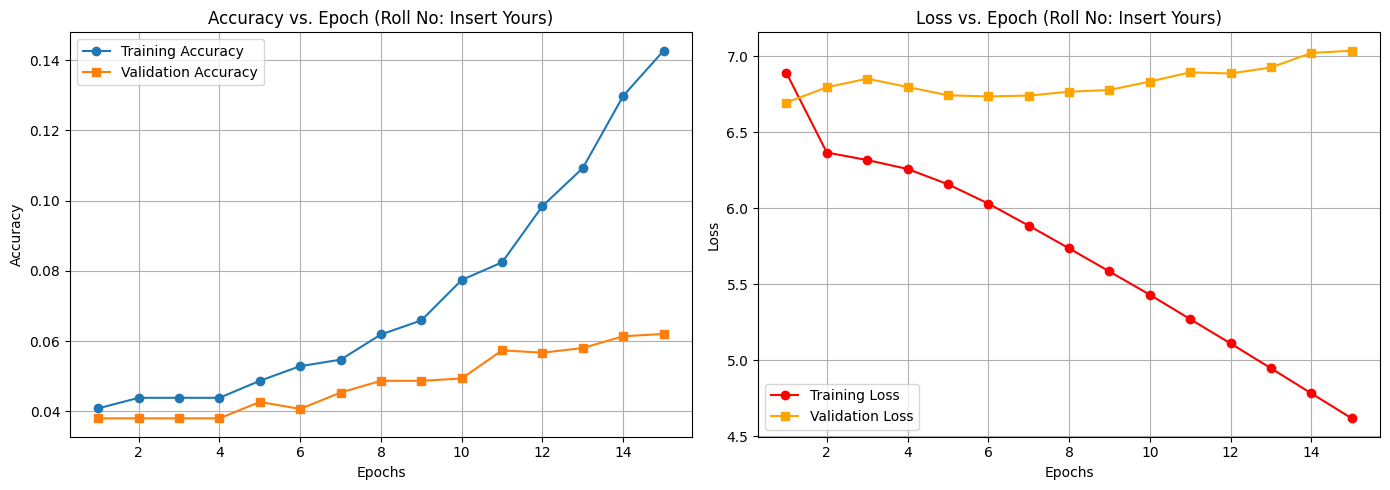

--- PART C COMPLETED ---


In [4]:
# =========================================================
# PART C: MODEL TRAINING & METRICS VISUALIZATION
# =========================================================
import matplotlib.pyplot as plt
print("--- PART C START ---")
# 1 & 2. Train the RNN model with validation
EPOCHS = 15
BATCH_SIZE = 128
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)
# 3. Record metrics
final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]
final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]
print("\n--- FINAL TRAINING METRICS ---")
print(f"Training Accuracy   : {final_train_acc:.4f}")
print(f"Validation Accuracy : {final_val_acc:.4f}")
print(f"Training Loss       : {final_train_loss:.4f}")
print(f"Validation Loss     : {final_val_loss:.4f}")
# 4. Visualize Accuracy & Loss curves
epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(14, 5))
# Plot 1: Accuracy vs Epoch
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy', marker='s')
plt.title('Accuracy vs. Epoch (Roll No: Insert Yours)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
# Plot 2: Loss vs Epoch
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'], label='Training Loss', marker='o', color='red')
plt.plot(epochs_range, history.history['val_loss'], label='Validation Loss', marker='s', color='orange')
plt.title('Loss vs. Epoch (Roll No: Insert Yours)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
print("--- PART C COMPLETED ---")

In [5]:
# =========================================================
# PART D: TEXT GENERATION & ANALYSIS
# =========================================================
print("--- PART D START ---")
# Function for text generation
def generate_text(seed_text, next_words=10, max_sequence_len=max_sequence_len):
    result = seed_text
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_sequence_len-1, padding='pre')
        # Predict probabilities and get the highest probability word
        predicted_probs = model.predict(token_list, verbose=0)
        predicted_index = np.argmax(predicted_probs, axis=-1)[0]
        output_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted_index:
                output_word = word
                break
        seed_text += " " + output_word
        result += " " + output_word
    return result
# 1 & 2. Seed Inputs & Dynamic Word Generation
seed_inputs = ["first citizen", "to be or not", "good lord", "speak to"]

print("--- GENERATED TEXT SAMPLES ---")
for seed in seed_inputs:
    generated_result = generate_text(seed, next_words=12)
    print(f"\nSeed Input : '{seed}'")
    print(f"Generated  : '{generated_result}'")

print("\n--- OBSERVATIONS & COHERENCE ANALYSIS ---")
print("""
1. The model captures basic syntactic dependencies and frequent vocabulary collocations from Shakespeare's text.
2. Short sequence context results in grammatically structured phrases near the seed, but coherence degrades as prediction chain grows longer.
3. Simple RNN architectures suffer from vanishing gradients, limiting long-range context preservation compared to standard LSTM/GRU models.
""")

print("--- PART D COMPLETED ---")

--- PART D START ---
--- GENERATED TEXT SAMPLES ---

Seed Input : 'first citizen'
Generated  : 'first citizen to rome to rome and as to the people in the people'

Seed Input : 'to be or not'
Generated  : 'to be or not in the people of the people than conduct the people are the'

Seed Input : 'good lord'
Generated  : 'good lord of the people in the people in the people than i have'

Seed Input : 'speak to'
Generated  : 'speak to the people of the people than that i have not in the'

--- OBSERVATIONS & COHERENCE ANALYSIS ---

1. The model captures basic syntactic dependencies and frequent vocabulary collocations from Shakespeare's text.
2. Short sequence context results in grammatically structured phrases near the seed, but coherence degrades as prediction chain grows longer.
3. Simple RNN architectures suffer from vanishing gradients, limiting long-range context preservation compared to standard LSTM/GRU models.

--- PART D COMPLETED ---
